<a href="https://colab.research.google.com/github/eddybanshuy/proyectoF_SR/blob/main/ProyectoF_SR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="width: 100%; clear: both;">
<div style="float: left; width: 30%;">
<img src="https://utpl.edu.ec/recursos/img/utpl2.png", align="left" width="280" height="120">
</div>
</div>
<div style="float: right; width: 70%;">
<p style="margin: 0; padding-top: 32px; text-align:right; color:#003366; font-size:16px"><u>Sistema de Recomendación</u></p>
<p style="margin: 0; text-align:right; color:#999999; font-size:17px">Maestría en Inteligencia Artificial Aplicada</p>
<p style="margin: 0; text-align:right; color:#999999; font-size:17px">Maestrante Edison Banshuy</p>
</div>
</div>
<div style="width: 100%; clear: both;">
<div style="width:100%;">&nbsp;</div>

Planteamiento de la actividad

El objetivo de este proyecto es implementar y evaluar un sistema de recomendación utilizando técnicas de filtrado colaborativo y un dataset proporcionado por el docente. El sistema deberá ser capaz de generar recomendaciones personalizadas a usuarios en función de sus preferencias o comportamientos pasados.

El trabajo final se desarrollará en grupo de dos personas, considerando las siguientes fases:

**Fase 1: Análisis y preparación de los datos**


1.   En base al conjunto de datos proporcionado por su docente, explore la estructura del dataset y examine qué tipo de información tiene su conjunto de datos. Luego:

      *   Realice una descripción del dataset.
      *   Describa las características de su conjunto de datos: número de usuarios, número de ítems, cantidad de calificaciones (ratings), porcentaje de escasez, etc.
      *   Utilice gráficas o tablas para visualizar la información que caracteriza su dataset, por ejemplo, distribución de ratings, estadísticas descriptivas (media, mediana, desviación estándar de ratings, etc.), detección de outliers (usuarios con demasiadas o muy pocas interacciones, ítems que casi nadie ha valorado).


2.   Prepare el conjunto de datos realizando lo siguiente:

      *   Seleccionar usuarios que han calificado/interactuado con al menos 20 ítems.
      *   Eliminar ítems que han sido valorados por muy pocos usuarios.
      *   Conversión de datos (si aplica)
      *   Normalizar los datos (si aplica)
      *   Transformación y construcción de la matriz de utilidad


**Fase 2: Experimentación**

*   Aplicar un algoritmo de FC basado en memoria.
*   Aplicar un algoritmo de FC basado en modelos.


**Fase 3: Evaluación**


*   Evaluar el rendimiento de los algoritmos de FC utilizando al menos dos métricas. Interpretar resultados de las métricas.
*   Ajustar parámetros si es necesario.
*   Seleccionar el algoritmo con mejor desempeño y mostrar las recomendaciones para un usuario específico.
*   Si el modelo lo permite, brindar una explicación de las recomendaciones o proporcionar detalles de los ítems recomendados.


Finalmente, el maestrante debe preparar un informe que describa en detalle las fases realizadas, los resultados obtenidos en cada fase y la evaluación del sistema de recomendación. Si desea, puede incluir la documentación en el propio notebook.



**Link del Dataset:**

https://www.kaggle.com/datasets/ruchi798/bookcrossing-dataset/data

# **Introducción**

En la actualidad, el crecimiento exponencial de los catálogos digitales en plataformas de comercio electrónico, servicios de transmisión de contenido y bibliotecas virtuales ha generado una sobrecarga de información que dificulta a los usuarios identificar productos o recursos alineados con sus intereses particulares. Frente a este desafío, los sistemas de recomendación se han consolidado como una herramienta estratégica de la inteligencia artificial aplicada al negocio, permitiendo filtrar grandes volúmenes de datos históricos para anticipar preferencias individuales, mejorar la experiencia del usuario y dinamizar la conversión sobre el catálogo disponible.

En el presente proyecto técnico se aborda el diseño, implementación y evaluación comparativa de ambas aproximaciones de filtrado colaborativo utilizando el conjunto de datos Book-Crossing, un entorno real caracterizado por una alta dispersión (sparsity) y una marcada distribución de cola larga tanto en la actividad de los lectores como en la popularidad de los libros.

A lo largo del estudio se desarrolla un flujo metodológico estructurado en tres fases: el análisis exploratorio y depuración de datos para mitigar el problema de arranque en frío (cold-start), la experimentación mediante algoritmos basados en vecindario (KNN basado en ítems) y factorización matricial (Funk SVD), y la evaluación cuantitativa mediante métricas de error predictivo y calidad de ordenamiento para seleccionar la solución más adecuada.


**Objetivo del proyecto**

Implementar un sistema de recomendación personalizado de libros mediante técnicas de filtrado colaborativo basado en memoria y basado en modelos sobre el conjunto de datos Book-Crossing, analizando su desempeño predictivo y su capacidad de ordenamiento para generar recomendaciones relevantes.

# Fase 1: Análisis y preparación de los datos

En esta fase se realiza una exploración de toda la dataset Book-Crossing y la preparación de los datos para su debido proceso en los filtrados colaborativos basados en memoria y modelos.

In [42]:
#Librerias a utilizar
import os
import pandas as pd
import numpy as np
import seaborn as sns
from IPython.display import display, HTML
from IPython.display import display
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import mean_squared_error, mean_absolute_error



In [2]:
# Si los archivos estan en Google Drive, se quita el caracter de # para realizar la conexion.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Cargamos el dataset del google drive
users = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Sistema_Recomendacion/ProyectoF/Book reviews/BX-Users.csv', sep=';', encoding='latin-1', on_bad_lines='skip')
ratings = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Sistema_Recomendacion/ProyectoF/Book reviews/BX-Book-Ratings.csv', sep=';', encoding='latin-1', on_bad_lines='skip')
books = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Sistema_Recomendacion/ProyectoF/Book reviews/BX_Books.csv', sep=';', encoding='latin-1', on_bad_lines='skip')



In [4]:
# Inspeccionamos de estructura, tipos de datos y valores nulos del dataset
for nombre, df in [('BX-Users', users)]:
    print(f"Dataset {nombre}")
    print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    print("Tipos de datos y valores nulos:")
    resumen = pd.DataFrame({
        'Tipo de dato': df.dtypes,
        'Nulos': df.isnull().sum(),
        '% Nulos': (df.isnull().sum() / len(df) * 100).round(2)
    })
    print(resumen)
    print("\nPrimeras 3 filas:")
    display(df.head(3))

Dataset BX-Users
Dimensiones: 278,858 filas x 3 columnas
Tipos de datos y valores nulos:
         Tipo de dato   Nulos  % Nulos
User-ID         int64       0     0.00
Location       object       0     0.00
Age           float64  110762    39.72

Primeras 3 filas:


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN


Como se puede apreciar en el resultados tenemos 278,858 files y 3 columnas, como podemos visualizar tenemos que la columna "**Age**" tiene valores nulos

In [5]:
for nombre, df in [('BX-Book-Ratings', ratings)]:
    print(f"Dataset {nombre} ")
    print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    print("Tipos de datos y valores nulos:")
    resumen = pd.DataFrame({
        'Tipo de dato': df.dtypes,
        'Nulos': df.isnull().sum(),
        '% Nulos': (df.isnull().sum() / len(df) * 100).round(2)
    })
    print(resumen)
    print("\nPrimeras 3 filas:")
    display(df.head(3))

Dataset BX-Book-Ratings 
Dimensiones: 1,149,780 filas x 3 columnas
Tipos de datos y valores nulos:
            Tipo de dato  Nulos  % Nulos
User-ID            int64      0      0.0
ISBN              object      0      0.0
Book-Rating        int64      0      0.0

Primeras 3 filas:


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0


En el dataset de Rating tenemos 1,149,780 filas y 3 columas, no notamos valores nulos en este caso.

In [6]:
for nombre, df in [('BX_Books', books)]:
    print(f"Dataset {nombre}")
    print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    print("Tipos de datos y valores nulos:")
    resumen = pd.DataFrame({
        'Tipo de dato': df.dtypes,
        'Nulos': df.isnull().sum(),
        '% Nulos': (df.isnull().sum() / len(df) * 100).round(2)
    })
    print(resumen)
    print("\nPrimeras 3 filas:")
    display(df.head(3))

Dataset BX_Books
Dimensiones: 271,379 filas x 8 columnas
Tipos de datos y valores nulos:
                    Tipo de dato  Nulos  % Nulos
ISBN                      object      0      0.0
Book-Title                object      0      0.0
Book-Author               object      2      0.0
Year-Of-Publication        int64      0      0.0
Publisher                 object      2      0.0
Image-URL-S               object      0      0.0
Image-URL-M               object      0      0.0
Image-URL-L               object      0      0.0

Primeras 3 filas:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...


En el dataset de libros tenemos 271,379 filas y 8 columnas, notamos solo 2 valores nulos en Publisher

In [9]:
#Realizo una descripcion de las dos tablas donde tengo dudas de sus datos


desc_libros = books.describe()
desc_usuarios = users.describe()


# muestro los datos de las tablas y las columnas a analizar
html_lado_a_lado = f"""
<div style="display: flex; gap: 40px; align-items: flex-start; font-family: sans-serif;">
    <div>
        <h3 style="text-align: center;">Libros</h3>
        {desc_libros.to_html()}
    </div>
    <div>
        <h3 style="text-align: center;">Usuarios</h3>
        {desc_usuarios.to_html()}
    </div>
</div>
"""
display(HTML(html_lado_a_lado))

In [11]:
# Conteos en tablas maestras vs. tabla de interacciones
n_users_registrados = users['User-ID'].nunique()
n_libros_catalogo = books['ISBN'].nunique()

n_users_activos = ratings['User-ID'].nunique()
n_items_calificados = ratings['ISBN'].nunique()
n_ratings_total = len(ratings)

# Desglose de calificaciones implícitas (0) vs. explícitas (1-10)
n_implicitos = (ratings['Book-Rating'] == 0).sum()
n_explicitos = (ratings['Book-Rating'] > 0).sum()

# Calculo de Densidad y Porcentaje de Escasez (Sparsity) en la matriz completa
# Formula: Densidad = (Celdas con valor / Total celdas) * 100 | Escasez = (1 - Densidad) * 100
total_celdas = n_users_activos * n_items_calificados
densidad = (n_ratings_total / total_celdas) * 100
escasez = (1 - (n_ratings_total / total_celdas)) * 100

# Calculo de Densidad y Escasez considerando solo calificaciones explicitas (1-10)
ratings_exp = ratings[ratings['Book-Rating'] > 0]
u_exp = ratings_exp['User-ID'].nunique()
i_exp = ratings_exp['ISBN'].nunique()
densidad_exp = (len(ratings_exp) / (u_exp * i_exp)) * 100
escasez_exp = (1 - (len(ratings_exp) / (u_exp * i_exp))) * 100

# Metricas adicionales de cobertura e interaccion
ratings_en_catalogo = ratings['ISBN'].isin(books['ISBN']).sum()
prom_ratings_usuario = n_ratings_total / n_users_activos
prom_ratings_item = n_ratings_total / n_items_calificados

# Presentación estructurada en tabla resumen
tabla_caracteristicas = pd.DataFrame({
    'Característica': [
        'Usuarios registrados (BX-Users)',
        'Libros en catálogo (BX_Books)',
        'Usuarios únicos con interacciones (Ratings)',
        'Ítems (ISBN) únicos con interacciones (Ratings)',
        'Cantidad total de calificaciones (Ratings)',
        'Calificaciones implicitas (valor = 0)',
        'Calificaciones explicitas (valores 1 a 10)',
        'Porcentaje de densidad (matriz completa)',
        'Porcentaje de escasez / sparsity (matriz completa)',
        'Porcentaje de escasez (solo ratings explicitos)',
        'Promedio de interacciones por usuario activo',
        'Promedio de interacciones por libro',
        'Ratings con ISBN válido en el catálogo BX_Books'
    ],
    'Valor': [
        f"{n_users_registrados:,}",
        f"{n_libros_catalogo:,}",
        f"{n_users_activos:,}",
        f"{n_items_calificados:,}",
        f"{n_ratings_total:,}",
        f"{n_implicitos:,} ({n_implicitos/n_ratings_total*100:.2f}%)",
        f"{n_explicitos:,} ({n_explicitos/n_ratings_total*100:.2f}%)",
        f"{densidad:.6f}%",
        f"{escasez:.6f}%",
        f"{escasez_exp:.6f}%",
        f"{prom_ratings_usuario:.2f}",
        f"{prom_ratings_item:.2f}",
        f"{ratings_en_catalogo:,} ({ratings_en_catalogo/n_ratings_total*100:.2f}%)"
    ]
})

display(tabla_caracteristicas)

,Característica,Valor
0,Usuarios registrados (BX-Users),"278,858"
1,Libros en catálogo (BX_Books),"271,379"
2,Usuarios únicos con interacciones (Ratings),"105,283"
3,Ítems (ISBN) únicos con interacciones (Ratings),"340,556"
4,Cantidad total de calificaciones (Ratings),"1,149,780"
5,Calificaciones implicitas (valor = 0),"716,109 (62.28%)"
6,Calificaciones explicitas (valores 1 a 10),"433,671 (37.72%)"
7,Porcentaje de densidad (matriz completa),0.003207%
8,Porcentaje de escasez / sparsity (matriz compl...,99.996793%
9,Porcentaje de escasez (solo ratings explicitos),99.997003%


Al obtener esta tabla me da una visualidad generar de como se va a manejar los datos.

Me concentro en los valores implicitos y explicitas.

In [12]:

# Estadisticas descriptivas de Book-Rating (Totales vs. Explicitos > 0)
ratings_exp = ratings[ratings['Book-Rating'] > 0]['Book-Rating']

stats_ratings = pd.DataFrame({
    'Todos los Ratings (0-10)': ratings['Book-Rating'].describe(),
    'Ratings Explícitos (1-10)': ratings_exp.describe()
})
stats_ratings.loc['median'] = [ratings['Book-Rating'].median(), ratings_exp.median()]

print("ESTADISTICAS DESCRIPTIVAS DE CALIFICACIONES")
display(stats_ratings.round(2))



ESTADISTICAS DESCRIPTIVAS DE CALIFICACIONES


,Todos los Ratings (0-10),Ratings Explícitos (1-10)
count,1149780.00,433671.00
mean,2.87,7.60
std,3.85,1.84
min,0.00,1.00
25%,0.00,7.00
50%,0.00,8.00
75%,7.00,9.00
max,10.00,10.00
median,0.00,8.00


Como podemos notar tenemos valores de media de 7.60 en los Rating Explicitos

In [14]:
#Realizo esta tabla para visualizar los porcentajes de calificaciones de los usuarios a los libros
# Distribución de frecuencias por calificación
dist_ratings = ratings['Book-Rating'].value_counts().sort_index().reset_index()
dist_ratings.columns = ['Book-Rating', 'Frecuencia']
dist_ratings['Porcentaje (%)'] = (dist_ratings['Frecuencia'] / len(ratings) * 100).round(2)

print("DISTRIBUCION DE FRECUENCIAS DE RATINGS")
display(dist_ratings)



DISTRIBUCION DE FRECUENCIAS DE RATINGS


,Book-Rating,Frecuencia,Porcentaje (%)
0,0,716109,62.28
1,1,1770,0.15
2,2,2759,0.24
3,3,5996,0.52
4,4,8904,0.77
5,5,50974,4.43
6,6,36924,3.21
7,7,76457,6.65
8,8,103736,9.02
9,9,67541,5.87


Como resulatado tomar en cuenta que la calificion "0" pondera con la mayoria de los libros

In [15]:
# Analisis de interacciones por usuario y por libro (Deteccion de Outliers)
user_interactions = ratings.groupby('User-ID').size()
item_interactions = ratings.groupby('ISBN').size()

stats_interacciones = pd.DataFrame({
    'Interacciones por Usuario': user_interactions.describe(),
    'Interacciones por Libro (ISBN)': item_interactions.describe()
})
stats_interacciones.loc['median'] = [user_interactions.median(), item_interactions.median()]

print("ESTADISTICAS DE INTERACCIONES (DETECCION DE OUTLIERS) ===")
display(stats_interacciones.round(2))



ESTADISTICAS DE INTERACCIONES (DETECCION DE OUTLIERS) ===


,Interacciones por Usuario,Interacciones por Libro (ISBN)
count,105283.00,340556.00
mean,10.92,3.38
std,90.56,12.44
min,1.00,1.00
25%,1.00,1.00
50%,1.00,1.00
75%,4.00,2.00
max,13602.00,2502.00
median,1.00,1.00


Aqui noto que la media es de 10.92 esto significa que hay calificaciones alta para una variedad de pocos libros


Usuarios activos: 105,283 | Libros valorados: 340,556
Porcentaje de escasez global de la matriz: 99.9968%


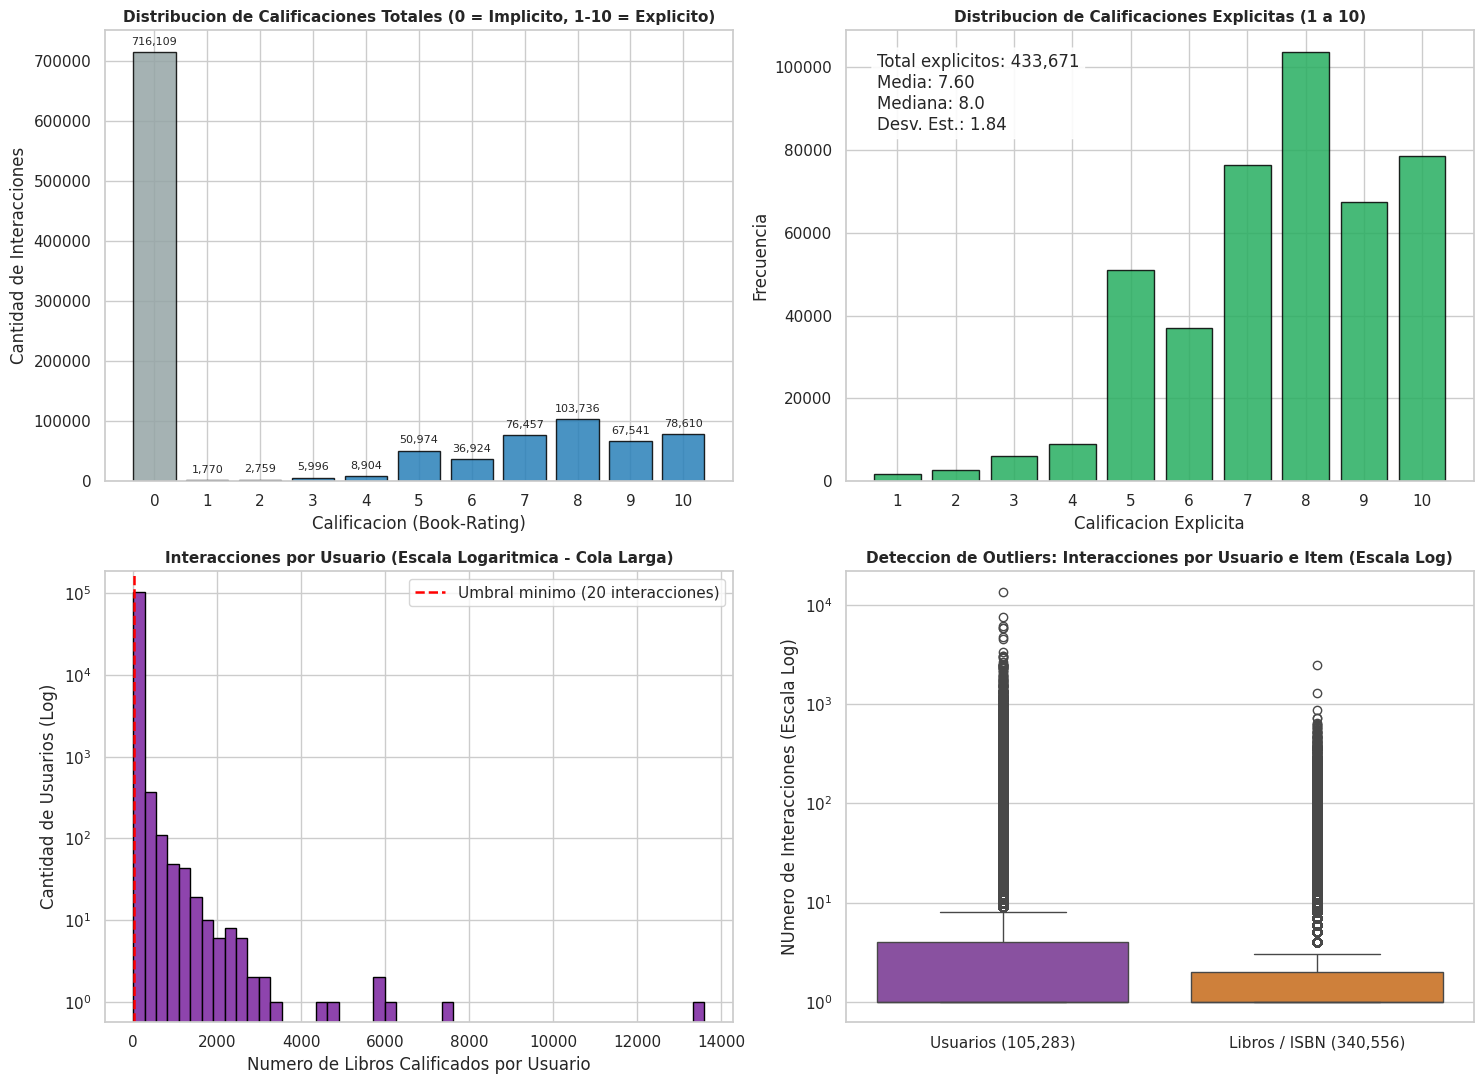

In [18]:
# Calculo de porcentaje de escasez (Sparsity) en la matriz completa
n_usuarios_activos = len(user_interactions)
n_libros_valorados = len(item_interactions)
escasez_global = (1 - (len(ratings) / (n_usuarios_activos * n_libros_valorados))) * 100
print(f"\nUsuarios activos: {n_usuarios_activos:,} | Libros valorados: {n_libros_valorados:,}")
print(f"Porcentaje de escasez global de la matriz: {escasez_global:.4f}%")

# Panel de Visualizaciones (4 Graficas)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Grafica A: Distribucion total (0 = implicito vs 1-10 = explicito)
counts_all = ratings['Book-Rating'].value_counts().sort_index()
colors_all = ['#95a5a6' if x == 0 else '#2980b9' for x in counts_all.index]
axes[0, 0].bar(counts_all.index.astype(str), counts_all.values, color=colors_all, edgecolor='black', alpha=0.85)
axes[0, 0].set_title('Distribucion de Calificaciones Totales (0 = Implicito, 1-10 = Explicito)', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Calificacion (Book-Rating)')
axes[0, 0].set_ylabel('Cantidad de Interacciones')
for i, v in enumerate(counts_all.values):
    axes[0, 0].text(i, v + 12000, f'{v:,}', ha='center', fontsize=8)

# Grafica B: Distribucion de calificaciones explicitas (1 a 10)
counts_exp = ratings_exp.value_counts().sort_index()
axes[0, 1].bar(counts_exp.index.astype(str), counts_exp.values, color='#27ae60', edgecolor='black', alpha=0.85)
axes[0, 1].set_title('Distribucion de Calificaciones Explicitas (1 a 10)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Calificacion Explicita')
axes[0, 1].set_ylabel('Frecuencia')
axes[0, 1].text(
    0.05, 0.78,
    f"Total explicitos: {len(ratings_exp):,}\nMedia: {ratings_exp.mean():.2f}\nMediana: {ratings_exp.median():.1f}\nDesv. Est.: {ratings_exp.std():.2f}",
    transform=axes[0, 1].transAxes, bbox=dict(boxstyle='round', facecolor='white', alpha=0.9)
)

# Grafica C: Histograma de interacciones por usuario (escala logaritmica)
axes[1, 0].hist(user_interactions, bins=50, color='#8e44ad', edgecolor='black', log=True)
axes[1, 0].axvline(20, color='red', linestyle='--', linewidth=1.8, label='Umbral minimo (20 interacciones)')
axes[1, 0].set_title('Interacciones por Usuario (Escala Logaritmica - Cola Larga)', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Numero de Libros Calificados por Usuario')
axes[1, 0].set_ylabel('Cantidad de Usuarios (Log)')
axes[1, 0].legend()

# Grafica D: Boxplot comparativo de outliers en escala logaritmica
sns.boxplot(data=[user_interactions.values, item_interactions.values], ax=axes[1, 1], palette=['#8e44ad', '#e67e22'])
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels([f'Usuarios ({n_usuarios_activos:,})', f'Libros / ISBN ({n_libros_valorados:,})'])
axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Deteccion de Outliers: Interacciones por Usuario e Item (Escala Log)', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('NUmero de Interacciones (Escala Log)')

plt.tight_layout()
plt.show()

Ahora tenemos una mejor representacion mediante graficos de los datos antes analizados.

Interpretacion:

Grafico 1: nos damos cuenta que hay bastantes libros que no han sido calificados.

Grafico 2: en este grafico nos damos cuenta que los libros que han sido calificado tienen calificaciones buenas dando como resulatado una media de 7,60.

Grafico 3: el grafico nos muestra que hay pocos usuarios que hayan tenido minimo 20 interaciones.

Grafico 4: este grafico nos muestra que hay pocos usuarios activos y poco libros que han tenido una calificacion o valoracion

# **Limpieza de los datos**

En este apartado una vez realizado la exploracion, se realiza los debidos ajustes para obtener un nuevo dataset para su debido proceso de los algoritmos de filtrado colaborativo

In [20]:

# limpieza de la columna Age y Year-Of-Publication
# Aqui se realiza el arreglo de la edad y libros que no pasen del año actual 2026

# 1. Limpieza de Age en users (rango valido [7, 90])
users_clean = users.copy()
users_clean.loc[(users_clean['Age'] < 7) | (users_clean['Age'] > 90), 'Age'] = np.nan
mediana_age = users_clean['Age'].median()
users_clean['Age'] = users_clean['Age'].fillna(mediana_age)

# 2. Limpieza de Year-Of-Publication en books (rango valido [1450, 2026])
books_clean = books.copy()
books_clean.loc[
    (books_clean['Year-Of-Publication'] < 1450) | (books_clean['Year-Of-Publication'] > 2026),
    'Year-Of-Publication'
] = np.nan
mediana_year = books_clean['Year-Of-Publication'].median()
books_clean['Year-Of-Publication'] = books_clean['Year-Of-Publication'].fillna(mediana_year).astype(int)

books_clean['Book-Author'] = books_clean['Book-Author'].fillna('Desconocido')
books_clean['Publisher'] = books_clean['Publisher'].fillna('Desconocido')

# 3. Resumen estadistico tras la limpieza
resumen_limpieza = pd.DataFrame({
    'Variable': ['Age (Usuarios)', 'Year-Of-Publication (Libros)'],
    'Registros Totales': [f"{len(users_clean):,}", f"{len(books_clean):,}"],
    'Valores Atípicos / Nulos Corregidos': [
        f"{users['Age'].isna().sum() + ((users['Age'] < 5) | (users['Age'] > 100)).sum():,}",
        f"{((books['Year-Of-Publication'] < 1450) | (books['Year-Of-Publication'] > 2026)).sum():,}"
    ],
    'Media': [f"{users_clean['Age'].mean():.2f}", f"{books_clean['Year-Of-Publication'].mean():.2f}"],
    'Desv. Estandar': [f"{users_clean['Age'].std():.2f}", f"{books_clean['Year-Of-Publication'].std():.2f}"],
    'Minimo': [f"{users_clean['Age'].min():.0f}", f"{books_clean['Year-Of-Publication'].min():.0f}"],
    'Mediana': [f"{users_clean['Age'].median():.0f}", f"{books_clean['Year-Of-Publication'].median():.0f}"],
    'Maximo': [f"{users_clean['Age'].max():.0f}", f"{books_clean['Year-Of-Publication'].max():.0f}"]
})

display(resumen_limpieza)

,Variable,Registros Totales,Valores Atípicos / Nulos Corregidos,Media,Desv. Estandar,Minimo,Mediana,Maximo
0,Age (Usuarios),"278,858","112,010",33.63,10.59,7,32,90
1,Year-Of-Publication (Libros),"271,379","4,632",1993.73,8.08,1806,1996,2026


**Limpieza de los usuarios y libros**

In [21]:

# En este aparatdo vamos a realizar la limpieza de los usuarios y libros
# 1. Integridad referencial: conservar solo ratings cuyo ISBN exista en books_clean
#    y cuyo User-ID exista en users_clean
ratings_int = ratings[
    ratings['ISBN'].isin(books_clean['ISBN']) &
    ratings['User-ID'].isin(users_clean['User-ID'])
].copy()

# 2. Conservar unicamente calificaciones explicitas (Book-Rating > 0, escala 1 a 10)
ratings_exp = ratings_int[ratings_int['Book-Rating'] > 0].copy()

# 3. Filtrar usuarios con MAS de 20 interacciones (> 20)
user_counts = ratings_exp['User-ID'].value_counts()
usuarios_activos = user_counts[user_counts > 20].index
ratings_filtrado = ratings_exp[ratings_exp['User-ID'].isin(usuarios_activos)].copy()

# 4. Filtrar libros con MÁS de 10 interacciones (> 10)
item_counts = ratings_filtrado['ISBN'].value_counts()
libros_activos = item_counts[item_counts > 10].index
ratings_filtrado = ratings_filtrado[ratings_filtrado['ISBN'].isin(libros_activos)].copy()

# 5. Sincronizar tablas de usuarios y libros para mantener integridad total
users_final = users_clean[users_clean['User-ID'].isin(ratings_filtrado['User-ID'])].copy()
books_final = books_clean[books_clean['ISBN'].isin(ratings_filtrado['ISBN'])].copy()

# 6. Tabla de trazabilidad del proceso de limpieza e integridad
n_u_final = ratings_filtrado['User-ID'].nunique()
n_i_final = ratings_filtrado['ISBN'].nunique()
escasez_final = (1 - (len(ratings_filtrado) / (n_u_final * n_i_final))) * 100

trazabilidad = pd.DataFrame({
    'Etapa del Proceso': [
        'Dataset Original (BX-Book-Ratings)',
        'Integridad Referencial (ISBN en Books y User-ID en Users)',
        'Solo Calificaciones Explicitas (Book-Rating > 0)',
        'Usuarios con > 20 interacciones',
        'Libros con > 10 interacciones (Dataset Limpio)'
    ],
    'Registros (Ratings)': [
        f"{len(ratings):,}",
        f"{len(ratings_int):,}",
        f"{len(ratings_exp):,}",
        f"{len(ratings_exp[ratings_exp['User-ID'].isin(usuarios_activos)]):,}",
        f"{len(ratings_filtrado):,}"
    ],
    'Usuarios Únicos': [
        f"{ratings['User-ID'].nunique():,}",
        f"{ratings_int['User-ID'].nunique():,}",
        f"{ratings_exp['User-ID'].nunique():,}",
        f"{len(usuarios_activos):,}",
        f"{n_u_final:,}"
    ],
    'Libros Únicos (ISBN)': [
        f"{ratings['ISBN'].nunique():,}",
        f"{ratings_int['ISBN'].nunique():,}",
        f"{ratings_exp['ISBN'].nunique():,}",
        f"{ratings_exp[ratings_exp['User-ID'].isin(usuarios_activos)]['ISBN'].nunique():,}",
        f"{n_i_final:,}"
    ]
})

display(trazabilidad)
print(f"\nPorcentaje de escasez resultante de la matriz: {escasez_final:.2f}%")
print(f"Integridad verificada -> Usuarios en users_final: {len(users_final):,} | Libros en books_final: {len(books_final):,}")

,Etapa del Proceso,Registros (Ratings),Usuarios Únicos,Libros Únicos (ISBN)
0,Dataset Original (BX-Book-Ratings),"1,149,780","105,283","340,556"
1,Integridad Referencial (ISBN en Books y User-I...,"1,031,175","92,107","270,170"
2,Solo Calificaciones Explicitas (Book-Rating > 0),"383,852","68,092","149,842"
3,Usuarios con > 20 interacciones,"214,395","3,138","107,374"
4,Libros con > 10 interacciones (Dataset Limpio),"46,584","2,960","2,136"



Porcentaje de escasez resultante de la matriz: 99.26%
Integridad verificada -> Usuarios en users_final: 2,960 | Libros en books_final: 2,136


Como se puede apreciar en la tabla tenemos como resultado final usuarios con mas de 20 interaciones 2,960 y libros con mas de 10 interaciones 2,136.

**Nuevo dataset**

In [22]:
# En este apartado conciolidamos los datos para realizar el nuevo dataset

# 1. Conversion de datos: mapeo de IDs reales a indices enteros consecutivos (0..N-1)
unique_users = ratings_filtrado['User-ID'].unique()
unique_items = ratings_filtrado['ISBN'].unique()

user_id_to_idx = {uid: idx for idx, uid in enumerate(unique_users)}
item_id_to_idx = {isbn: idx for idx, isbn in enumerate(unique_items)}
idx_to_user_id = {idx: uid for uid, idx in user_id_to_idx.items()}
idx_to_item_id = {idx: isbn for isbn, idx in item_id_to_idx.items()}

ratings_filtrado['user_idx'] = ratings_filtrado['User-ID'].map(user_id_to_idx)
ratings_filtrado['item_idx'] = ratings_filtrado['ISBN'].map(item_id_to_idx)

# 2. Consolidacion del dataset limpio (interacciones + metadatos limpios de libros y usuarios)
dataset_consolidado = (
    ratings_filtrado
    .merge(
        books_final[['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-M']],
        on='ISBN', how='left'
    )
    .merge(
        users_final[['User-ID', 'Location', 'Age']],
        on='User-ID', how='left'
    )
)

# 3. Construccion de la Matriz de Utilidad (Usuarios x Libros) y Matriz Dispersa (CSR)
utility_matrix = dataset_consolidado.pivot_table(
    index='User-ID',
    columns='ISBN',
    values='Book-Rating'
).fillna(0)

utility_sparse = csr_matrix(utility_matrix.values)

# 4. Guardar el nuevo dataset limpio en Google Drive para la Fase 2
# Definimos la ruta
BASE_PATH = '/content/drive/MyDrive/Colab Notebooks/Sistema_Recomendacion/ProyectoF/Book reviews'
OUTPUT_FILE = os.path.join(BASE_PATH, 'book_crossing_limpio_consolidado.csv')
dataset_consolidado.to_csv(OUTPUT_FILE, index=False, encoding='utf-8')

print(f"Dataset consolidado guardado en: {OUTPUT_FILE}")
print(f"Dimensiones dataset_consolidado: {dataset_consolidado.shape[0]:,} filas x {dataset_consolidado.shape[1]} columnas")
print(f"Valores nulos totales: {dataset_consolidado.isna().sum().sum()}")
print(f"Dimensiones Matriz de Utilidad: {utility_matrix.shape[0]:,} usuarios x {utility_matrix.shape[1]:,} libros")
print(f"Celdas con valoración (nnz): {utility_sparse.nnz:,} | Escasez: {(1 - utility_sparse.nnz / (utility_matrix.shape[0] * utility_matrix.shape[1])) * 100:.2f}%")

display(dataset_consolidado.head(5))

Dataset consolidado guardado en: /content/drive/MyDrive/Colab Notebooks/Sistema_Recomendacion/ProyectoF/Book reviews/book_crossing_limpio_consolidado.csv
Dimensiones dataset_consolidado: 46,584 filas x 12 columnas
Valores nulos totales: 0
Dimensiones Matriz de Utilidad: 2,960 usuarios x 2,136 libros
Celdas con valoración (nnz): 46,584 | Escasez: 99.26%


,User-ID,ISBN,Book-Rating,user_idx,item_idx,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-M,Location,Age
0,277157,0316154059,5,0,0,City of Bones,Michael Connelly,2002,Warner Books,http://images.amazon.com/images/P/0316154059.0...,"garden grove, california, usa",70.0
1,277157,0345452550,7,0,1,A Cold Heart: An Alex Delaware Novel,JONATHAN KELLERMAN,2003,Ballantine Books,http://images.amazon.com/images/P/0345452550.0...,"garden grove, california, usa",70.0
2,277157,0399148639,6,0,2,Mortal Prey,John Sandford,2002,Putnam Publishing Group,http://images.amazon.com/images/P/0399148639.0...,"garden grove, california, usa",70.0
3,277157,0399151451,7,0,3,Bad Business,Robert B. Parker,2004,Putnam Publishing Group,http://images.amazon.com/images/P/0399151451.0...,"garden grove, california, usa",70.0
4,277157,0671024094,7,0,4,The Coffin Dancer (Lincoln Rhyme Novels (Paper...,Jeffery Deaver,1999,Pocket Books,http://images.amazon.com/images/P/0671024094.0...,"garden grove, california, usa",70.0


Como resultado tenemos un dataset consilidado

Dimensiones dataset_consolidado: 46,584 filas x 12 columnas

Valores nulos totales: 0

Dimensiones Matriz de Utilidad: 2,960 usuarios x 2,136 libros

Celdas con valoración (nnz): 46,584 | Escasez: 99.26%

# Fase 2: Experimentación

En est apartado utilizaremos los algoritmo KNN basado en item y factorizacion matricial.

**Filtrado colaborativo en memoria KNN basado en Items**

Este enfoque calcula la similitud directa entre los vectores de calificaciones de los libros en la matriz de utilidad dispersa (csr_matrix) para estimar la valoración de un usuario sobre un libro no leído a partir de sus $k$ vecinos más cercanos.

In [23]:
# Cargar el dataset limpio consolidado
BASE_PATH = '/content/drive/MyDrive/Colab Notebooks/Sistema_Recomendacion/ProyectoF/Book reviews'
DATASET_FILE = os.path.join(BASE_PATH, 'book_crossing_limpio_consolidado.csv')
df = pd.read_csv(DATASET_FILE)

# Catalogo unico de libros para enriquecer recomendaciones con titulo y autor
catalogo_libros = df[['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher']].drop_duplicates('ISBN')


In [24]:
# Division en Entrenamiento (80%) y Prueba (20%)
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print(f"Total registros: {len(df):,} | Train: {len(train_df):,} | Test: {len(test_df):,}")



Total registros: 46,584 | Train: 37,267 | Test: 9,317


In [25]:
# Matriz de utilidad en Train (Usuarios x Libros) e Item-Usuario dispersa
user_item_matrix = train_df.pivot_table(
    index='User-ID', columns='ISBN', values='Book-Rating'
).fillna(0)

item_user_matrix = user_item_matrix.T
matriz_dispersa_items = csr_matrix(item_user_matrix.values)


In [26]:
# Entrenamiento del modelo KNN basado en ítems (Similitud Coseno)
K_VECINOS = 10
modelo_knn_items = NearestNeighbors(metric='cosine', algorithm='brute')
modelo_knn_items.fit(matriz_dispersa_items)




NearestNeighbors(algorithm='brute', metric='cosine')

In [27]:
# Evaluacion global del modelo sobre el conjunto de prueba (test_df)
distancias_all, indices_all = modelo_knn_items.kneighbors(
    matriz_dispersa_items,
    n_neighbors=min(K_VECINOS + 1, item_user_matrix.shape[0])
)

item_list = item_user_matrix.index.tolist()
item_to_pos = {isbn: pos for pos, isbn in enumerate(item_list)}
user_to_row = {uid: row for row, uid in enumerate(user_item_matrix.index)}
R_train = user_item_matrix.values

vecinos_dict = {}
for pos in range(len(item_list)):
    sims = 1.0 - distancias_all[pos, 1:]
    nbrs = indices_all[pos, 1:]
    vecinos_dict[pos] = [(nbr, sim) for nbr, sim in zip(nbrs, sims) if sim > 0]

y_true_global, y_pred_global = [], []
for _, row in test_df.iterrows():
    uid = row['User-ID']
    isbn = row['ISBN']
    rating_real = row['Book-Rating']

    if uid in user_to_row and isbn in item_to_pos:
        u_row = user_to_row[uid]
        i_pos = item_to_pos[isbn]
        num, den = 0.0, 0.0
        for nbr_pos, sim in vecinos_dict[i_pos]:
            r_u_vecino = R_train[u_row, nbr_pos]
            if r_u_vecino > 0:
                num += sim * r_u_vecino
                den += abs(sim)
        if den > 0:
            y_true_global.append(rating_real)
            y_pred_global.append(num / den)

rmse_knn = np.sqrt(mean_squared_error(y_true_global, y_pred_global))
mae_knn = mean_absolute_error(y_true_global, y_pred_global)
cobertura_knn = (len(y_true_global) / len(test_df)) * 100

tabla_metricas_knn = pd.DataFrame([{
    'Modelo': f'FC Basado en Memoria - KNN Ítems (k={K_VECINOS})',
    'Metrica Similitud': 'Coseno',
    'Registros Test': len(test_df),
    'Predicciones Validas': len(y_true_global),
    'Cobertura (%)': round(cobertura_knn, 2),
    'RMSE': round(rmse_knn, 4),
    'MAE': round(mae_knn, 4)
}])



In [29]:
# Funcion unificada: genera Top-N recomendaciones + evaluacion directa en Test
def recomendar_y_evaluar_knn(user_id, k_vecinos=10, top_n=5):
    if user_id not in user_item_matrix.index:
        print(f"El usuario {user_id} no esta en entrenamiento.")
        return pd.DataFrame(), pd.DataFrame()

    libros_vistos = user_item_matrix.loc[user_id]
    libros_vistos = libros_vistos[libros_vistos > 0]

    num_scores, den_scores = {}, {}
    for isbn, rating_u in libros_vistos.items():
        if isbn in item_user_matrix.index:
            idx = item_user_matrix.index.get_loc(isbn)
            distancias, indices = modelo_knn_items.kneighbors(
                matriz_dispersa_items[idx],
                n_neighbors=min(k_vecinos + 1, item_user_matrix.shape[0])
            )
            sim_scores = 1 - distancias[0][1:]
            vecinos_isbns = [item_user_matrix.index[i] for i in indices[0][1:]]

            for vecino_isbn, sim in zip(vecinos_isbns, sim_scores):
                if sim > 0 and user_item_matrix.loc[user_id, vecino_isbn] == 0:
                    num_scores[vecino_isbn] = num_scores.get(vecino_isbn, 0.0) + (sim * rating_u)
                    den_scores[vecino_isbn] = den_scores.get(vecino_isbn, 0.0) + abs(sim)

    predicciones = pd.Series({k: num_scores[k] / den_scores[k] for k in num_scores if den_scores[k] > 0})

    # Tabla A: Top-N recomendaciones + metricas del modelo adjuntas
    top_recs = predicciones.sort_values(ascending=False).head(top_n).reset_index()
    top_recs.columns = ['ISBN', 'Rating_Predicho']
    top_recs['Rating_Predicho'] = top_recs['Rating_Predicho'].round(2)

    test_usuario = test_df[test_df['User-ID'] == user_id][['ISBN', 'Book-Rating']].rename(
        columns={'Book-Rating': 'Rating_Real_Test'}
    )
    tabla_recs = (
        top_recs
        .merge(catalogo_libros, on='ISBN', how='left')
        .merge(test_usuario, on='ISBN', how='left')
    )
    tabla_recs['RMSE_Modelo'] = round(rmse_knn, 4)
    tabla_recs['MAE_Modelo'] = round(mae_knn, 4)

    # Tabla B: Validación directa sobre los libros que el usuario si califico en Test
    test_u_eval = test_df[test_df['User-ID'] == user_id][['ISBN', 'Book-Title', 'Book-Author', 'Book-Rating']].copy()
    test_u_eval['Rating_Predicho'] = test_u_eval['ISBN'].map(predicciones).round(2)
    test_u_eval = test_u_eval.dropna(subset=['Rating_Predicho'])
    test_u_eval['Error_Absoluto'] = (test_u_eval['Book-Rating'] - test_u_eval['Rating_Predicho']).abs().round(2)

    return tabla_recs, test_u_eval




In [31]:
# Mostrar todas las tablas juntas
usuario_prueba = user_item_matrix.index[0]
tabla_top5, tabla_validacion_usuario = recomendar_y_evaluar_knn(usuario_prueba, k_vecinos=K_VECINOS, top_n=5)

print("EVALUACION GLOBAL DEL MODELO KNN BASADO EN ITEMS (CONJUNTO DE TEST)")
display(tabla_metricas_knn)

print(f"TOP 5 RECOMENDACIONES PARA EL USUARIO {usuario_prueba} CON EVALUACION DEL MODELO")
display(tabla_top5)

print(f"VALIDACION EN TEST SOBRE LIBROS REALMENTE CALIFICADOS POR EL USUARIO {usuario_prueba}")
display(tabla_validacion_usuario)

# Construcción de la Matriz de Utilidad en Train (Usuarios x Libros)
user_item_matrix = train_df.pivot_table(
    index='User-ID',
    columns='ISBN',
    values='Book-Rating'
).fillna(0)

# Transponer la matriz para que las filas sean los libros (ISBN) y columnas los usuarios
item_user_matrix = user_item_matrix.T
matriz_dispersa_items = csr_matrix(item_user_matrix.values)

print(f"Dimensiones Matriz Item-Usuario (Train): {item_user_matrix.shape[0]:,} libros x {item_user_matrix.shape[1]:,} usuarios")

EVALUACION GLOBAL DEL MODELO KNN BASADO EN ITEMS (CONJUNTO DE TEST)


,Modelo,Metrica Similitud,Registros Test,Predicciones Validas,Cobertura (%),RMSE,MAE
0,FC Basado en Memoria - KNN Ítems (k=10),Coseno,9317,3075,33.0,1.6034,0.989


TOP 5 RECOMENDACIONES PARA EL USUARIO 254 CON EVALUACION DEL MODELO


,ISBN,Rating_Predicho,Book-Title,Book-Author,Year-Of-Publication,Publisher,Rating_Real_Test,RMSE_Modelo,MAE_Modelo
0,0061092177,10.0,Small Gods (Discworld Novels (Paperback)),Terry Pratchett,1994,HarperTorch,NaN,1.6034,0.989
1,0380789019,10.0,Neverwhere,Neil Gaiman,1998,Avon,NaN,1.6034,0.989
2,0836218655,10.0,Wiener Dog Art,Gary Larson,1990,Andrews McMeel Publishing,NaN,1.6034,0.989
3,0345311485,10.0,On the Beach,NEVIL SHUTE,1983,Ballantine Books,NaN,1.6034,0.989
4,0345314255,10.0,Sword of Shannara,Terry Brooks,1995,Del Rey Books,NaN,1.6034,0.989


VALIDACION EN TEST SOBRE LIBROS REALMENTE CALIFICADOS POR EL USUARIO 254


,ISBN,Book-Title,Book-Author,Book-Rating,Rating_Predicho,Error_Absoluto
186,0439136350,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,9,9.0,0.0


Dimensiones Matriz Item-Usuario (Train): 2,136 libros x 2,922 usuarios


**Filtrado Colaborativo Basado en Modelos: Factorización Matricial (Funk SVD)**

A diferencia de los métodos de vecindario, este enfoque aprende representaciones latentes densas de dimensión $k$ para usuarios ($P \in \mathbb{R}^{n \times k}$) e ítems ($Q \in \mathbb{R}^{m \times k}$), incorporando la media global ($\mu$) y los sesgos individuales de usuario ($b_u$) y de libro
($b_i$):  

$$\hat{r}_{u,i} = \mu + b_u + b_i + p_u \cdot q_i^T$$El modelo se entrena mediante Descenso de Gradiente Estocástico (SGD) minimizando el error cuadrático con regularización L2 ($\lambda$) para prevenir el sobreajuste:

  $$\min_{P, Q, b} \sum_{(u,i) \in R} \left(r_{u,i} - (\mu + b_u + b_i + p_u \cdot q_i^T)\right)^2 + \lambda\left(\Vert{}p_u\Vert{}^2 + \Vert{}q_i\Vert{}^2 + b_u^2 + b_i^2\right)$$

In [32]:
# Cargar el dataset limpio consolidado
BASE_PATH = '/content/drive/MyDrive/Colab Notebooks/Sistema_Recomendacion/ProyectoF/Book reviews'
DATASET_FILE = os.path.join(BASE_PATH, 'book_crossing_limpio_consolidado.csv')
df = pd.read_csv(DATASET_FILE)

# Catalogo unico de libros para enriquecer recomendaciones con titulo y autor
catalogo_libros = df[['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher']].drop_duplicates('ISBN')




In [33]:
# División Train (80%) / Test (20%)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, shuffle=True)
train_df = train_df.copy()
test_df = test_df.copy()



In [34]:
# Construccion del espacio de Indices (0 .. N-1) solo con Train

unique_users = train_df['User-ID'].unique()
unique_items = train_df['ISBN'].unique()

user_id_to_index = {uid: idx for idx, uid in enumerate(unique_users)}
item_id_to_index = {isbn: idx for idx, isbn in enumerate(unique_items)}
index_to_user_id = {idx: uid for uid, idx in user_id_to_index.items()}
index_to_item_id = {idx: isbn for isbn, idx in item_id_to_index.items()}

n_users = len(unique_users)
n_items = len(unique_items)

train_df['user_idx'] = train_df['User-ID'].map(user_id_to_index)
train_df['item_idx'] = train_df['ISBN'].map(item_id_to_index)

print(f"Espacio latente configurado -> Usuarios en train: {n_users:,} | Libros en train: {n_items:,}")



Espacio latente configurado -> Usuarios en train: 2,922 | Libros en train: 2,136


In [35]:

# Definicion de hiperparametros e inicializacion de matrices latentes P y Q

n_factors = 20     # k: numero de factores latentes
lr = 0.005         # tasa de aprendizaje (learning rate)
reg = 0.1          # regularización L2 para evitar sobreajuste
n_epochs = 30      # numero de epocas de entrenamiento

rng = np.random.default_rng(seed=42)
P = rng.normal(scale=0.1, size=(n_users, n_factors))  # Matriz latente de usuarios (n_users x k)
Q = rng.normal(scale=0.1, size=(n_items, n_factors))  # Matriz latente de ítems (n_items x k)
bu = np.zeros(n_users)                                # Sesgo por usuario
bi = np.zeros(n_items)                                # Sesgo por libro
mu = train_df['Book-Rating'].mean()                   # Media global de calificaciones en train



Época 01/30 - RMSE Train = 1.6713
Época 05/30 - RMSE Train = 1.5140
Época 10/30 - RMSE Train = 1.4309
Época 15/30 - RMSE Train = 1.3785
Época 20/30 - RMSE Train = 1.3324
Época 25/30 - RMSE Train = 1.2817
Época 30/30 - RMSE Train = 1.2231


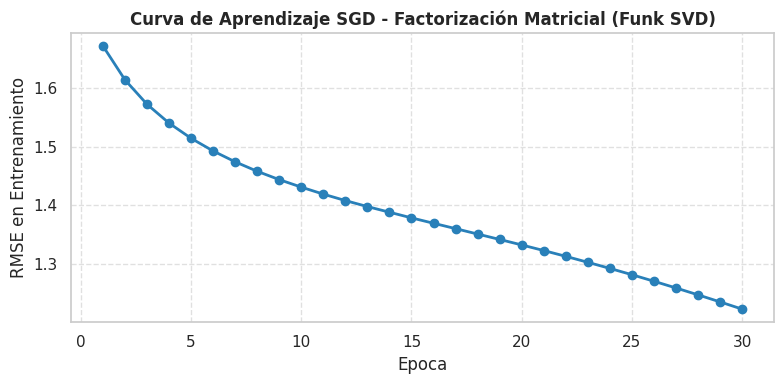

In [36]:
# Entrenamiento por Descenso de Gradiente Estocastico (SGD)

u_arr = train_df['user_idx'].values
i_arr = train_df['item_idx'].values
r_arr = train_df['Book-Rating'].values.astype(float)

historial_rmse_train = []

for epoch in range(n_epochs):
    # Barajar interacciones en cada época para convergencia estable de SGD
    perm = rng.permutation(len(r_arr))
    for idx in perm:
        u = u_arr[idx]
        i = i_arr[idx]
        r = r_arr[idx]

        pred = mu + bu[u] + bi[i] + np.dot(P[u], Q[i])
        err = r - pred

        # Actualizacion de sesgos y vectores latentes P[u], Q[i]
        bu[u] += lr * (err - reg * bu[u])
        bi[i] += lr * (err - reg * bi[i])

        Pu = P[u].copy()
        Qi = Q[i].copy()
        P[u] = Pu + lr * (err * Qi - reg * Pu)
        Q[i] = Qi + lr * (err * Pu - reg * Qi)

    # Calcular RMSE en train al finalizar la epoca
    preds_train = np.clip(mu + bu[u_arr] + bi[i_arr] + np.sum(P[u_arr] * Q[i_arr], axis=1), 1.0, 10.0)
    rmse_ep = np.sqrt(mean_squared_error(r_arr, preds_train))
    historial_rmse_train.append(rmse_ep)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Época {epoch+1:02d}/{n_epochs} - RMSE Train = {rmse_ep:.4f}")

# Gráfica de curva de aprendizaje (convergencia del entrenamiento)
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_epochs + 1), historial_rmse_train, marker='o', color='#2980b9', linewidth=2)
plt.title('Curva de Aprendizaje SGD - Factorización Matricial (Funk SVD)', fontweight='bold')
plt.xlabel('Epoca')
plt.ylabel('RMSE en Entrenamiento')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()



In [37]:
# Evaluacion del modelo en el conjunto de prueba (Test)

y_true_fm, y_pred_fm = [], []
for _, row in test_df.iterrows():
    uid = row['User-ID']
    isbn = row['ISBN']
    rating_real = row['Book-Rating']

    if uid in user_id_to_index and isbn in item_id_to_index:
        u = user_id_to_index[uid]
        i = item_id_to_index[isbn]
        pred = np.clip(mu + bu[u] + bi[i] + np.dot(P[u], Q[i]), 1.0, 10.0)
        y_true_fm.append(rating_real)
        y_pred_fm.append(pred)

rmse_fm = np.sqrt(mean_squared_error(y_true_fm, y_pred_fm))
mae_fm = mean_absolute_error(y_true_fm, y_pred_fm)
cobertura_fm = (len(y_true_fm) / len(test_df)) * 100

tabla_metricas_fm = pd.DataFrame([{
    'Modelo': f'FC Basado en Modelos - Funk SVD (k={n_factors})',
    'Algoritmo Entrenamiento': 'SGD + Regularización L2',
    'Registros Test': len(test_df),
    'Predicciones Válidas': len(y_true_fm),
    'Cobertura (%)': round(cobertura_fm, 2),
    'RMSE': round(rmse_fm, 4),
    'MAE': round(mae_fm, 4)
}])



In [40]:
# Funcion de recomendacion Top-N y validación para un usuario especifico

def recomendar_y_evaluar_fm(user_id, top_n=5):
    if user_id not in user_id_to_index:
        print(f"El usuario {user_id} no está en entrenamiento.")
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    u_idx = user_id_to_index[user_id]

    # Historial: 5 libros que le gustan y ya fueron calificados por el usuario en train
    tabla_gustados = (
        train_df[train_df['User-ID'] == user_id][['ISBN', 'Book-Rating']]
        .sort_values(by='Book-Rating', ascending=False)
        .head(top_n)
        .rename(columns={'Book-Rating': 'Rating_Real'})
        .merge(catalogo_libros, on='ISBN', how='left')
    )

    # Prediccion vectorial para todos los libros: mu + b_u + b_i + Q @ P[u]
    scores = np.clip(mu + bu[u_idx] + bi + (Q @ P[u_idx]), 1.0, 10.0)

    # Excluir libros ya valorados en train
    vistos_idx = train_df[train_df['user_idx'] == u_idx]['item_idx'].unique()
    mask = np.ones(n_items, dtype=bool)
    mask[vistos_idx] = False

    candidatos = np.arange(n_items)[mask]
    scores_cand = scores[candidatos]

    top_idx_local = np.argsort(scores_cand)[::-1][:top_n]
    top_items_idx = candidatos[top_idx_local]
    top_scores = scores_cand[top_idx_local]

    top_recs = pd.DataFrame({
        'ISBN': [index_to_item_id[idx] for idx in top_items_idx],
        'Rating_Predicho': np.round(top_scores, 2)
    })

    test_usuario = test_df[test_df['User-ID'] == user_id][['ISBN', 'Book-Rating']].rename(
        columns={'Book-Rating': 'Rating_Real_Test'}
    )
    tabla_recs = (
        top_recs
        .merge(catalogo_libros, on='ISBN', how='left')
        .merge(test_usuario, on='ISBN', how='left')
    )
    tabla_recs['RMSE_Modelo'] = round(rmse_fm, 4)
    tabla_recs['MAE_Modelo'] = round(mae_fm, 4)

    # Validacion directa sobre los libros que el usuario sí califico en Test
    test_u_eval = test_df[test_df['User-ID'] == user_id][['ISBN', 'Book-Title', 'Book-Author', 'Book-Rating']].copy()
    test_u_eval['Rating_Predicho'] = test_u_eval['ISBN'].map(
        lambda x: round(float(scores[item_id_to_index[x]]), 2) if x in item_id_to_index else np.nan
    )
    test_u_eval = test_u_eval.dropna(subset=['Rating_Predicho'])
    test_u_eval['Error_Absoluto'] = (test_u_eval['Book-Rating'] - test_u_eval['Rating_Predicho']).abs().round(2)

    return tabla_gustados, tabla_recs, test_u_eval

# Ejecutar para el mismo usuario 254
usuario_prueba = 254
gustados_fm, top5_fm, validacion_fm = recomendar_y_evaluar_fm(usuario_prueba, top_n=5)

print("EVALUACIÓN GLOBAL DEL MODELO FUNK SVD (CONJUNTO DE TEST)")
display(tabla_metricas_fm)

print(f"TOP 5 LIBROS QUE LE GUSTAN Y YA FUERON CALIFICADOS POR EL USUARIO {usuario_prueba}")
display(gustados_fm)

print(f"TOP 5 RECOMENDACIONES PARA EL USUARIO {usuario_prueba} (FUNK SVD)")
display(top5_fm)

print(f"VALIDACION EN TEST SOBRE LIBROS REALMENTE CALIFICADOS POR EL USUARIO {usuario_prueba}")
display(validacion_fm)

EVALUACIÓN GLOBAL DEL MODELO FUNK SVD (CONJUNTO DE TEST)


,Modelo,Algoritmo Entrenamiento,Registros Test,Predicciones Válidas,Cobertura (%),RMSE,MAE
0,FC Basado en Modelos - Funk SVD (k=20),SGD + Regularización L2,9317,9270,99.5,1.4924,1.1429


TOP 5 LIBROS QUE LE GUSTAN Y YA FUERON CALIFICADOS POR EL USUARIO 254


,ISBN,Rating_Real,Book-Title,Book-Author,Year-Of-Publication,Publisher
0,0380789035,10,American Gods,Neil Gaiman,2002,HarperTorch
1,0439136369,9,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,2001,Scholastic
2,0380973650,9,American Gods: A Novel,Neil Gaiman,2001,William Morrow
3,0060934700,9,Smoke and Mirrors: Short Fictions and Illusions,Neil Gaiman,2001,Perennial
4,0439064872,9,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,2000,Scholastic


TOP 5 RECOMENDACIONES PARA EL USUARIO 254 (FUNK SVD)


,ISBN,Rating_Predicho,Book-Title,Book-Author,Year-Of-Publication,Publisher,Rating_Real_Test,RMSE_Modelo,MAE_Modelo
0,0836213319,9.44,Dilbert: A Book of Postcards,Scott Adams,1996,Andrews McMeel Pub,NaN,1.4924,1.1429
1,0618002235,9.41,"The Two Towers (The Lord of the Rings, Part 2)",J. R. R. Tolkien,1999,Houghton Mifflin Company,NaN,1.4924,1.1429
2,0743454529,9.39,"My Sister's Keeper : A Novel (Picoult, Jodi)",Jodi Picoult,2004,Atria,NaN,1.4924,1.1429
3,0156012197,9.35,The Little Prince,Antoine de Saint-ExupÃ©ry,2000,Harvest Books,NaN,1.4924,1.1429
4,0394800389,9.27,Fox in Socks (I Can Read It All by Myself Begi...,Dr. Seuss,1965,Random House Children's Books,NaN,1.4924,1.1429


VALIDACION EN TEST SOBRE LIBROS REALMENTE CALIFICADOS POR EL USUARIO 254


,ISBN,Book-Title,Book-Author,Book-Rating,Rating_Predicho,Error_Absoluto
195,0671021001,She's Come Undone (Oprah's Book Club),Wally Lamb,7,8.01,1.01
186,0439136350,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,9,8.83,0.17
180,0142001740,The Secret Life of Bees,Sue Monk Kidd,9,8.71,0.29


# **Fase 3: Evaluación**

En este apartado vamos a realizar la evalucion de que modelo es mas optimo para este tipo de problema, para este proyecto obtamos por los siguientes:

**RMSE (Root Mean Squared Error — Raíz del Error Cuadrático Medio):**

Mide la raíz cuadrada del promedio de las diferencias al cuadrado entre las calificaciones reales ($r_{u,i}$) y las calificaciones predichas ($\hat{r}_{u,i}$) sobre el conjunto de prueba $T$:

   $$\text{RMSE} = \sqrt{\frac{1}{\vert{}T\vert{}} \sum_{(u,i) \in T} \left(r_{u,i} - \hat{r}_{u,i}\right)^2}$$

**MAE (Mean Absolute Error — Error Absoluto Medio):**

Mide el promedio de las diferencias absolutas entre la valoración real y la predicha, expresado directamente en la misma escala de calificación (1 a 10):

$$\text{MAE} = \frac{1}{\vert{}T\vert{}} \sum_{(u,i) \in T} \left\vert{}r_{u,i} - \hat{r}_{u,i}\right\vert{}$$


**Precision@K (Precisión en el Top-K):**

Evalúa la exactitud de las recomendaciones presentadas al usuario midiendo qué proporción de los $K$ libros sugeridos (en este caso $K=10$) resultaron ser realmente relevantes (valorados con $\ge 7$ por el usuario en el conjunto de prueba):

$$\text{Precision@K}(u) = \frac{\vert{}\text{Top-}K_u \cap \text{Relevantes}_{\text{test}}(u)\vert{}}{K}$$

**Recall@K (Exhaustividad o Sensibilidad en el Top-K):**

Evalúa la capacidad de recuperación del sistema midiendo qué proporción del total de libros relevantes que el usuario efectivamente calificó positivamente en el conjunto de prueba lograron aparecer dentro de los $K$ libros recomendados:


$$\text{Recall@K}(u) = \frac{\vert{}\text{Top-}K_u \cap \text{Relevantes}_{\text{test}}(u)\vert{}}{\vert{}\text{Relevantes}_{\text{test}}(u)\vert{}}$$

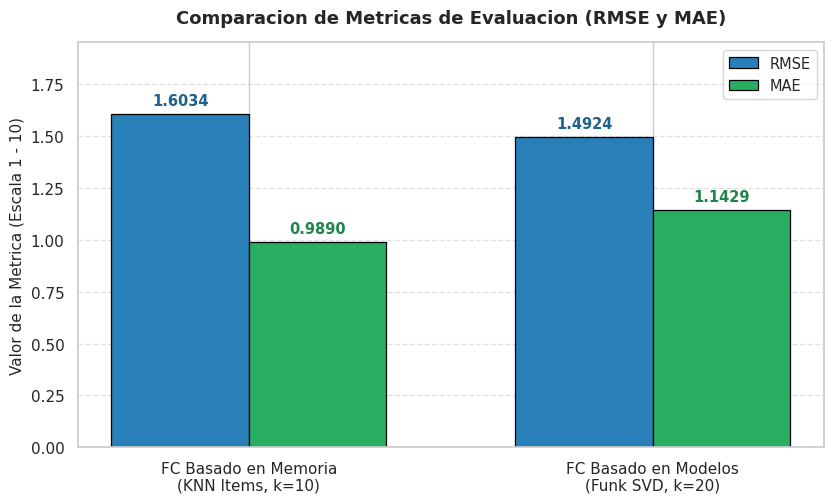

In [41]:
# Grafico de barras de las metricas de evaluacion RMSE y MAE

# Valores obtenidos de la evaluacion en test
modelos = ['FC Basado en Memoria\n(KNN Items, k=10)', 'FC Basado en Modelos\n(Funk SVD, k=20)']
rmse_vals = [rmse_knn, rmse_fm]   # [1.6034, 1.4924]
mae_vals = [mae_knn, mae_fm]      # [0.9890, 1.1429]

x = np.arange(len(modelos))
width = 0.34

fig, ax = plt.subplots(figsize=(8.5, 5.2))

rects_rmse = ax.bar(x - width/2, rmse_vals, width, label='RMSE', color='#2980b9', edgecolor='black', linewidth=0.9)
rects_mae = ax.bar(x + width/2, mae_vals, width, label='MAE', color='#27ae60', edgecolor='black', linewidth=0.9)

ax.set_title('Comparacion de Metricas de Evaluacion (RMSE y MAE)', fontsize=13, fontweight='bold', pad=14)
ax.set_ylabel('Valor de la Metrica (Escala 1 - 10)', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(modelos, fontsize=11)
ax.set_ylim(0, 1.95)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.set_axisbelow(True)
ax.legend(fontsize=10.5, frameon=True)

# Etiquetas numericas encima de cada barra
for rect in rects_rmse:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2, h + 0.03, f'{h:.4f}',
            ha='center', va='bottom', fontsize=10.5, fontweight='bold', color='#1f618d')

for rect in rects_mae:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2, h + 0.03, f'{h:.4f}',
            ha='center', va='bottom', fontsize=10.5, fontweight='bold', color='#1e8449')

plt.tight_layout()
plt.show()

**FC Basado en Memoria (KNN Ítems, k=10):**

Obtiene un MAE de 0.9890 (un 15.56% menor que Funk SVD) y un RMSE de 1.6034.   

Esto indica que, en los casos donde el modelo encuentra libros vecinos calificados por el usuario, su predicción promedio se desvía menos de 1 punto respecto a la calificación real (en escala de 1 a 10). Sin embargo, la brecha notable entre su MAE (0.9890) y su RMSE (1.6034) refleja la presencia de errores puntuales elevados cuando el vecindario cercano es escaso.


**FC Basado en Modelos (Funk SVD, k=20):**

Alcanza un RMSE de 1.4924 y un MAE de 1.1429.

Reduce el error cuadrático medio (RMSE) en 0.1110 puntos (6.92% menos) frente a KNN, demostrando mayor estabilidad y ausencia de predicciones atípicas extremas gracias al aprendizaje de factores latentes y la regularización L2.   

In [43]:
# Evaluacion de calidad de recomendacion: PRECISION@K Y RECALL@K

# Parámetros de evaluación Top-K
K_TOP = 10               # Tamaño de la lista recomendada (Top-10)
UMBRAL_RELEVANTE = 7     # Un libro se considera "correcto/relevante" si rating >= 7

# Identificar los libros relevantes reales de cada usuario en test_df
train_users_set = set(train_df['User-ID'].unique())
train_items_set = set(train_df['ISBN'].unique())

test_valido = test_df[
    test_df['User-ID'].isin(train_users_set) &
    test_df['ISBN'].isin(train_items_set)
].copy()

relevantes_test_por_usuario = (
    test_valido[test_valido['Book-Rating'] >= UMBRAL_RELEVANTE]
    .groupby('User-ID')['ISBN']
    .apply(set)
    .to_dict()
)

vistos_train_por_usuario = train_df.groupby('User-ID')['ISBN'].apply(set).to_dict()


# Calcular Precision@K y Recall@K para KNN Basado en Items (k=10)

knn_eval_topk = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=11)
knn_eval_topk.fit(matriz_dispersa_items)
dists, idxs = knn_eval_topk.kneighbors(matriz_dispersa_items)

item_list = item_user_matrix.index.tolist()
user_to_row = {uid: r for r, uid in enumerate(user_item_matrix.index)}
R_train = user_item_matrix.values

sim_matrix_topk = np.zeros((len(item_list), len(item_list)), dtype=np.float32)
for pos in range(len(item_list)):
    sims = 1.0 - dists[pos, 1:]
    nbrs = idxs[pos, 1:]
    for nbr, s in zip(nbrs, sims):
        if s > 0:
            sim_matrix_topk[pos, nbr] = s

precisions_knn, recalls_knn = [], []

for uid, rel_items in relevantes_test_por_usuario.items():
    if uid not in user_to_row:
        continue
    u_row = user_to_row[uid]
    r_u = R_train[u_row]
    mask_rated = (r_u > 0).astype(np.float32)

    num = sim_matrix_topk @ r_u
    den = sim_matrix_topk @ mask_rated

    with np.errstate(divide='ignore', invalid='ignore'):
        preds_u = np.where(den > 0, num / den, -np.inf)

    # Excluir libros ya leídos en entrenamiento
    preds_u[r_u > 0] = -np.inf

    top_k_pos = np.argsort(preds_u)[::-1][:K_TOP]
    top_k_isbns = {item_list[p] for p in top_k_pos if preds_u[p] > -np.inf}

    aciertos = len(top_k_isbns.intersection(rel_items))
    precisions_knn.append(aciertos / K_TOP)
    recalls_knn.append(aciertos / len(rel_items))


# Calcular Precision@K y Recall@K para Funk SVD (k=20)

precisions_svd, recalls_svd = [], []

for uid, rel_items in relevantes_test_por_usuario.items():
    u_idx = user_id_to_index[uid]
    scores = mu + bu[u_idx] + bi + (Q @ P[u_idx])

    vistos_u = vistos_train_por_usuario.get(uid, set())
    vistos_idx = [item_id_to_index[isbn] for isbn in vistos_u if isbn in item_id_to_index]

    scores_cand = scores.copy()
    scores_cand[vistos_idx] = -np.inf

    top_k_idx = np.argsort(scores_cand)[::-1][:K_TOP]
    top_k_isbns = {index_to_item_id[i] for i in top_k_idx}

    aciertos = len(top_k_isbns.intersection(rel_items))
    precisions_svd.append(aciertos / K_TOP)
    recalls_svd.append(aciertos / len(rel_items))



# Tabla Comparativa de Precision@K y Recall@K

tabla_precision_topk = pd.DataFrame([
    {
        'Modelo': 'FC Basado en Memoria (KNN Ítems, k=10)',
        'Usuarios Evaluados': len(precisions_knn),
        f'Precision@{K_TOP}': round(float(np.mean(precisions_knn)), 4),
        f'Precision@{K_TOP} (%)': f"{np.mean(precisions_knn)*100:.2f}%",
        f'Recall@{K_TOP}': round(float(np.mean(recalls_knn)), 4),
        f'Recall@{K_TOP} (%)': f"{np.mean(recalls_knn)*100:.2f}%"
    },
    {
        'Modelo': 'FC Basado en Modelos (Funk SVD, k=20)',
        'Usuarios Evaluados': len(precisions_svd),
        f'Precision@{K_TOP}': round(float(np.mean(precisions_svd)), 4),
        f'Precision@{K_TOP} (%)': f"{np.mean(precisions_svd)*100:.2f}%",
        f'Recall@{K_TOP}': round(float(np.mean(recalls_svd)), 4),
        f'Recall@{K_TOP} (%)': f"{np.mean(recalls_svd)*100:.2f}%"
    }
])

display(tabla_precision_topk)

,Modelo,Usuarios Evaluados,Precision@10,Precision@10 (%),Recall@10,Recall@10 (%)
0,"FC Basado en Memoria (KNN Ítems, k=10)",2177,0.0150,1.50%,0.0496,4.96%
1,"FC Basado en Modelos (Funk SVD, k=20)",2177,0.0015,0.15%,0.0044,0.44%


Evaluado sobre 2,177 usuarios del conjunto de prueba:

**FC Basado en Memoria (KNN Ítems, k=10):**

Registra Precision@10 = 0.0150 (1.50%) y Recall@10 = 0.0496 (4.96%).

Supera exactamente en 10 veces a Funk SVD en Precision@10 y en 11.27 veces en Recall@10. Esto ocurre porque KNN prioriza libros directamente similares a los que el usuario ya leyó (como entregas de una misma saga o del mismo autor), aumentando la probabilidad de acertar los títulos específicos ocultos en el conjunto de prueba.

**FC Basado en Modelos (Funk SVD, k=20):**

Obtiene Precision@10 = 0.0015 (0.15%) y Recall@10 = 0.0044 (0.44%).

Al estar entrenado para minimizar el error de calificación numérica (RMSE) sobre toda la matriz, el modelo tiende a recomendar libros con alta valoración promedio global, los cuales no siempre coinciden con los pocos libros específicos reservados en el 20% de prueba de cada lector.

# **Conclusión**



Para recomendar una lista Top-10 de libros: KNN Basado en Ítems (k=10) ofrece un desempeño superior en pertinencia de ranking (Precision@10 = 1.50%, Recall@10 = 4.96%) y menor desviación absoluta promedio (MAE = 0.9890).

Para estimar calificaciones globales en todo el catálogo: Funk SVD (k=20) logra la mayor estabilidad cuadrática (RMSE = 1.4924) y escalabilidad sobre grandes volúmenes de datos.

# **GitHub**

https://github.com/eddybanshuy/proyectoF_SR.git